# 03 — Sprint 6 : le modèle retenu est-il fiable partout ? (robustesse)

**But.** Le modèle retenu pour l'objectif 2 (GRU, trajectoire) a une erreur moyenne d'environ 6 points. Une moyenne
peut cacher des groupes de patients où le modèle se trompe beaucoup plus.

**Question.** Où le modèle se trompe-t-il ? On regarde l'erreur (MAE) par sous-groupe de patients, puis les résidus.

**Règle.** On utilise **seulement les prédictions hors-pli de la validation croisée** (patients du dev). Le test a déjà
servi une fois pour l'objectif 2 : le relire pour chercher des faiblesses reviendrait à l'utiliser pour décider.

**Plan.** 1. Les données · 2. Erreur par sous-groupe · 3. Les résidus · 4. Synthèse

In [1]:
# Configuration : chemins du projet
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(os.environ.get("PPMI_PROJECT_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
from IPython.display import Image, display
from parkinson_mm.utils.config import load_config

cfg = load_config(ROOT / "params.yaml")
R = cfg.robustesse                                   # params.yaml > robustesse
TABLES, FIGURES = ROOT / "reports/tables/robustesse", ROOT / "reports/figures/robustesse"
print(f"Modèle étudié : {R.modele} | référence : {R.reference}")

Modèle étudié : GRU – trajectoire (M1) | référence : Persistance


## 1. Les données : les prédictions hors-pli

**Pourquoi.** En validation croisée à 5 plis, chaque visite du dev est prédite par un modèle entraîné **sans** ce
patient. Ces prédictions « hors-pli » sont donc honnêtes, et on peut les analyser sans toucher au test.

Chaque exemple « visite i → visite i+1 » est rangé dans un groupe pour chaque critère (stade, état de l'examen, durée de
maladie, génétique, sexe, âge, période d'inclusion). Une donnée inconnue (par exemple un patient non génotypé) laisse
le groupe vide : l'exemple ne compte pas pour ce critère.

In [2]:
oof = pd.read_csv(ROOT / "reports/tables/models/cv_predictions.csv")          # sortie de l'étape train
mine = oof[oof["model"] == R.modele].reset_index(drop=True)
print(f"{len(mine)} prédictions hors-pli, {mine['PATNO'].nunique()} patients du dev, {mine['fold'].nunique()} plis")

errors = pd.read_csv(TABLES / "mae_par_groupe.csv")                           # sortie de l'étape robustesse
gru = errors[errors["modèle"] == R.modele]
gru.groupby("critère", sort=False).agg(groupes=("groupe", " · ".join), **{"exemples classés": ("exemples", "sum")})

8715 prédictions hors-pli, 1206 patients du dev, 5 plis


,groupes,exemples classés
critère,,
Stade (Hoehn & Yahr),H&Y 0–1 · H&Y 2 · H&Y ≥ 3,8710
État de l'examen à prédire,OFF · ON · sans traitement,8715
Durée de maladie,< 2 ans · 2–5 ans · > 5 ans,8714
Génétique,GBA · LRRK2 · non porteur,8427
Sexe,femme · homme,8715
Âge,< 60 ans · 60–70 ans · > 70 ans,8715
Période d'inclusion,≤ 2014 · 2015–2019 · ≥ 2020,8715


## 2. Où le modèle se trompe-t-il ? (MAE par sous-groupe)

**Méthode.** Dans chaque groupe : MAE du GRU et MAE de la persistance (« le score ne change pas ») dans le même groupe.
Le calcul est fait par l'étape DVC `robustesse` (`python scripts/run_robustesse.py`) ; on relit son tableau. Sur la
figure, les barres autour du point bleu montrent l'incertitude de la MAE du GRU : plus le groupe est petit, plus la
barre est longue.

In [3]:
gru = gru.set_index(["critère", "groupe"])
ref = errors[errors["modèle"] == R.reference].set_index(["critère", "groupe"])
table = pd.DataFrame({
    "exemples": gru["exemples"], "patients": gru["patients"],
    "MAE GRU": gru["MAE"].round(2),
    "MAE persistance": ref.loc[gru.index, "MAE"].round(2),
})
table["gain vs persistance"] = (table["MAE persistance"] - table["MAE GRU"]).round(2)
table

exemples  patients  MAE GRU  \
critère                    groupe                                         
Stade (Hoehn & Yahr)       H&Y 0–1              1785       580     4.65   
                           H&Y 2                6373      1108     6.23   
                           H&Y ≥ 3               552       228     8.54   
État de l'examen à prédire OFF                  3713       946     6.43   
                           ON                   2799       728     6.50   
                           sans traitement      2203       740     4.86   
Durée de maladie           < 2 ans              3085       961     5.16   
                           2–5 ans              3280       934     5.87   
                           > 5 ans              2349       487     7.49   
Génétique                  GBA                   623        81     7.26   
                           LRRK2                1338       151     6.77   
                           non porteur          6466       828     5.77   
Sexe                       femme                3311       468     6.27   
                           homme                5404       738     5.92   
Âge                        < 60 ans             2565       401     5.94   
                           60–70 ans            3357       659     6.03   
                           > 70 ans             2793       510     6.18   
Période d'inclusion        ≤ 2014               4886       385     5.95   
                           2015–2019            1211       172     7.15   
                           ≥ 2020               2618       649     5.74   

                                            MAE persistance  \
critère                    groupe                             
Stade (Hoehn & Yahr)       H&Y 0–1                     5.46   
                           H&Y 2                       7.26   
                           H&Y ≥ 3                     9.93   
État de l'examen à prédire OFF                         7.47   
                           ON                          7.83   
                           sans traitement             5.39   
Durée de maladie           < 2 ans                     5.88   
                           2–5 ans                     6.89   
                           > 5 ans                     8.84   
Génétique                  GBA                         8.62   
                           LRRK2                       8.04   
                           non porteur                 6.70   
Sexe                       femme                       7.22   
                           homme                       6.96   
Âge                        < 60 ans                    7.07   
                           60–70 ans                   6.95   
                           > 70 ans                    7.19   
Période d'inclusion        ≤ 2014                      7.01   
                           2015–2019                   8.51   
                           ≥ 2020                      6.49   

                                            gain vs persistance  
critère                    groupe                                
Stade (Hoehn & Yahr)       H&Y 0–1                         0.81  
                           H&Y 2                           1.03  
                           H&Y ≥ 3                         1.39  
État de l'examen à prédire OFF                             1.04  
                           ON                              1.33  
                           sans traitement                 0.53  
Durée de maladie           < 2 ans                         0.72  
                           2–5 ans                         1.02  
                           > 5 ans                         1.35  
Génétique                  GBA                             1.36  
                           LRRK2                           1.27  
                           non porteur                     0.93  
Sexe                       femme                           0.95  
                

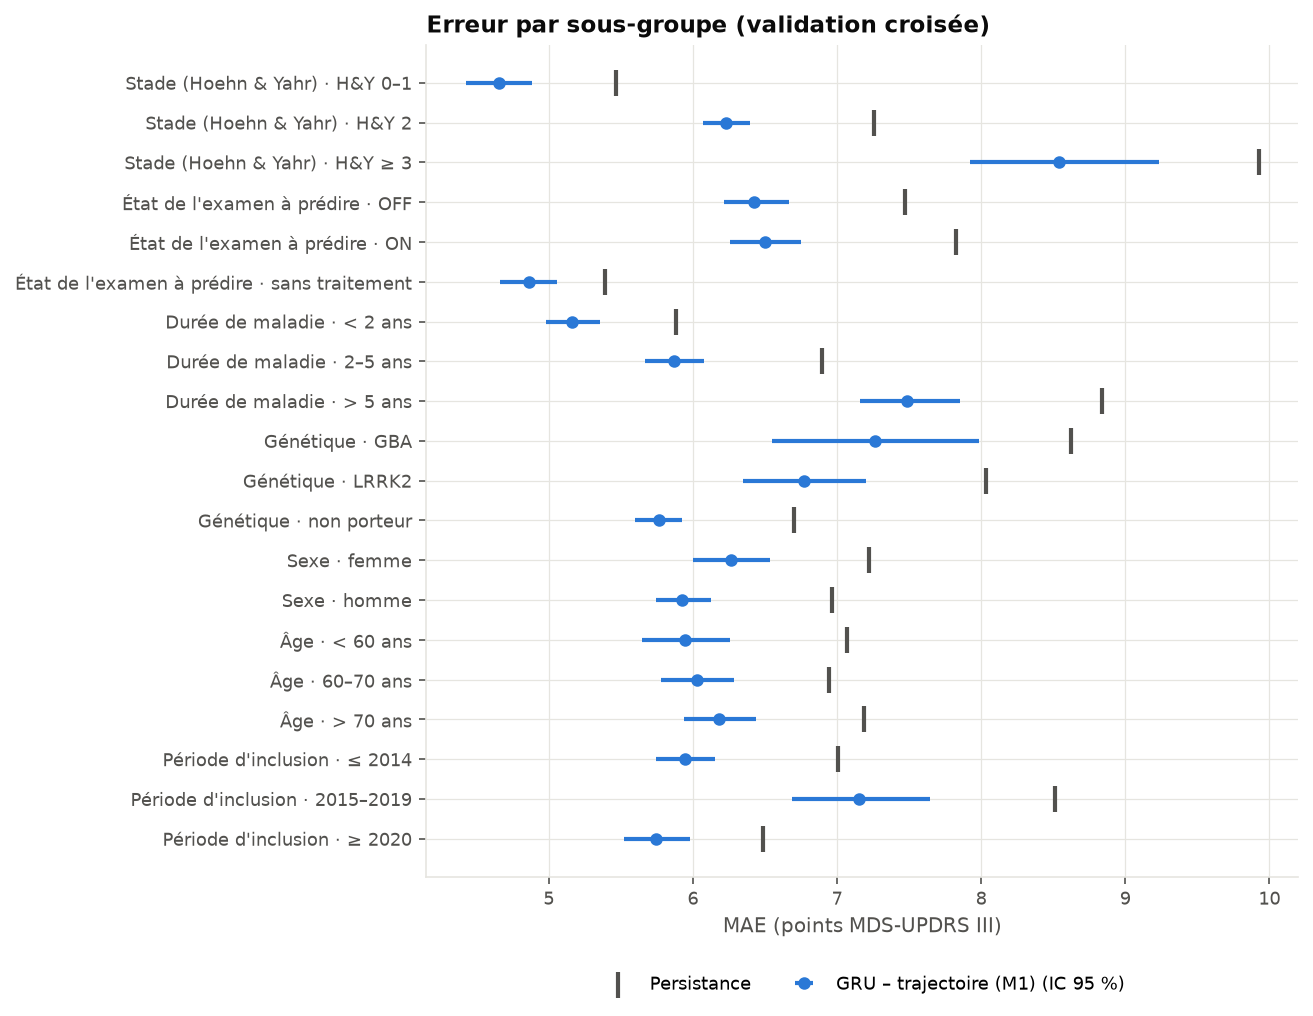

In [4]:
display(Image(FIGURES / "mae_par_groupe.png", width=720))   # figure produite par l'étape robustesse

**Observation.** Le GRU fait mieux que la persistance dans **les 20 sous-groupes** (gain de 0,5 à 1,7 point). Mais son
erreur n'est pas la même partout :

* elle monte avec le **stade** : 4,65 points en H&Y 0–1, 6,23 en H&Y 2, **8,54 en H&Y ≥ 3** ;
* elle monte avec la **durée de maladie** : 5,16 (< 2 ans) → 7,49 (> 5 ans) ;
* elle est plus basse quand la visite à prédire est **sans traitement** (4,86) qu'en OFF (6,43) ou ON (6,50) ;
* porteurs **GBA** 7,26 et **LRRK2** 6,77 contre 5,77 pour les non-porteurs (petits groupes : 81 et 151 patients) ;
* le sexe et l'âge changent peu l'erreur (5,92 à 6,27). La période 2015–2019 (7,15, 172 patients) est notée sans
  être interprétée.

**Pour la soutenance.** Le modèle est moins précis chez les patients avancés, dont les scores sont plus hauts et varient
plus d'une visite à l'autre. C'est la limite principale : on l'annonce, chiffres à l'appui.

## 3. Les résidus : le modèle se trompe-t-il dans un sens ?

Résidu = score réel − score prédit. On regroupe les exemples par niveau de score prédit, et on regarde la moyenne, la
médiane et l'étendue (10e et 90e percentiles) des résidus.

In [5]:
mine["résidu"] = mine["y"] - mine["pred"]
level = pd.cut(mine["pred"], [0, 15, 25, 35, 45, 132], labels=["< 15", "15–25", "25–35", "35–45", "≥ 45"])
print(f"Résidu global : moyenne {mine['résidu'].mean():+.2f} pt, médiane {mine['résidu'].median():+.2f} pt")
mine.groupby(level, observed=True)["résidu"].agg(
    exemples="size", moyenne="mean", médiane="median",
    p10=lambda r: r.quantile(0.1), p90=lambda r: r.quantile(0.9)).round(2).rename_axis("score prédit")

Résidu global : moyenne +0.58 pt, médiane +0.04 pt


,exemples,moyenne,médiane,p10,p90
score prédit,,,,,
< 15,1136,1.34,0.34,-5.33,9.10
15–25,3252,0.62,-0.11,-7.80,9.58
25–35,2670,0.58,0.12,-9.36,10.88
35–45,1144,0.14,-0.14,-11.49,11.87
≥ 45,513,-0.45,-0.11,-15.90,14.03


**Observation.** La médiane des résidus est proche de 0 dans chaque tranche : pas d'erreur systématique forte. Quand le
score prédit est bas (< 15), le vrai score est en moyenne un peu plus haut (+1,3 point). Surtout, l'étendue grandit avec
le score : de [−5,3 ; +9,1] sous 15 points à [−15,9 ; +14,0] au-dessus de 45. C'est le résultat de la section 2 vu
autrement : plus la maladie est avancée, plus le score est variable et difficile à prédire.

## 4. Synthèse

| Question | Réponse | Conséquence |
|---|---|---|
| Le GRU bat-il la persistance partout ? | oui, dans les 20 sous-groupes | le gain n'est pas porté par un seul groupe |
| Où se trompe-t-il le plus ? | stades avancés (H&Y ≥ 3 : 8,5 points), maladie > 5 ans, porteurs GBA | limite principale, annoncée |
| Y a-t-il une erreur dans un sens ? | non, médiane des résidus proche de 0 ; l'étendue grandit avec le score | plus la maladie avance, moins le score est prévisible |

Ces analyses n'ont servi à **aucun choix de modèle** et le test n'a pas été relu. Elles sont tracées dans l'experiment
MLflow `objectif2_robustesse` (un run, tableaux et figures en artefacts).